# LSTM Multi-Horizon Baseline — JalVaani

Direct h-step forecasting: **one LSTM per horizon** (t+7, t+14, t+30).

Each model uses a **30-day lookback** window and predicts `gwl_mean` exactly h days
after the last observed day. Windows are split by **target date**, not input date.

**Architecture** (identical to t+1 baseline for fair comparison):
```
ts_seq[30, 19] + static_soil[9] + district_embed[8]
  → LSTM(hidden=64, layers=2, dropout=0.2) → Linear(64→1)
```

> Training logs show per-epoch `train_loss / val_loss` with early stopping.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from pathlib import Path
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.size']  = 11

MASTER   = Path('../../Data Preprocessing/clean datasets/master_dataset.csv')
OUT_DIR  = Path('outputs')
PLOT_DIR = OUT_DIR / 'plots'
OUT_DIR.mkdir(exist_ok=True)
PLOT_DIR.mkdir(exist_ok=True)

LOOKBACK   = 30
HIDDEN_DIM = 64
NUM_LAYERS = 2
DROPOUT    = 0.2
EMBED_DIM  = 8
BATCH_SIZE = 128
LR         = 1e-3
MAX_EPOCHS = 100
PATIENCE   = 15
LR_PAT     = 5

TRAIN_END = '2024-09-30'
VAL_END   = '2025-01-31'
HORIZONS  = [7, 14, 30]
COLORS    = {7: '#e41a1c', 14: '#ff7f00', 30: '#377eb8'}

TIME_SERIES_COLS = [
    'gwl_lag_7','gwl_lag_14','gwl_lag_30',
    'gwl_7d_change','gwl_30d_change',
    'rainfall_mm','rainfall_7d','rainfall_30d',
    'et_mm','soil_moisture','net_water_balance',
    'temp_max','temp_min','temp_mean','humidity_mean','vpd_approx',
    'month','day_of_year','is_monsoon',
]
STATIC_COLS = [
    'sand_0cm','clay_0cm','silt_0cm',
    'sand_10cm','clay_10cm','silt_10cm',
    'sand_30cm','clay_30cm','silt_30cm',
]
TARGET = 'gwl_mean'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'Horizons: {HORIZONS}')
print(f'Lookback: {LOOKBACK} days')
print(f'Architecture: hidden={HIDDEN_DIM}, layers={NUM_LAYERS}, embed={EMBED_DIM}')

Device: cpu
Horizons: [7, 14, 30]
Lookback: 30 days
Architecture: hidden=64, layers=2, embed=8


## 1. Dataset & Model Definitions

In [2]:
class GWLDataset(Dataset):
    def __init__(self, windows): self.windows = windows
    def __len__(self): return len(self.windows)
    def __getitem__(self, idx):
        ts_seq, static, dist_id, target = self.windows[idx][:4]
        return (
            torch.tensor(ts_seq,  dtype=torch.float32),
            torch.tensor(static,  dtype=torch.float32),
            torch.tensor(dist_id, dtype=torch.long),
            torch.tensor(target,  dtype=torch.float32),
        )

def build_windows(df, ts_cols, static_cols, target_col, lookback, horizon,
                  train_end, val_end):
    train_end_ts = pd.Timestamp(train_end)
    val_end_ts   = pd.Timestamp(val_end)
    train_w, val_w, test_w = [], [], []

    for dist, grp in df.groupby('district'):
        grp   = grp.sort_values('date').reset_index(drop=True)
        ts    = grp[ts_cols].values.astype(float)
        stat  = grp[static_cols].values.astype(float)
        dids  = grp['district_id'].values.astype(int)
        tgts  = grp[target_col].values.astype(float)
        dates = grp['date'].values

        for i in range(lookback, len(grp) - horizon + 1):
            ts_seq = ts[i - lookback: i]
            if np.isnan(ts_seq).any(): continue
            target_val  = tgts[i + horizon - 1]
            if np.isnan(target_val): continue
            static_vec  = np.nan_to_num(stat[i].copy(), nan=0.0)
            target_date = pd.Timestamp(dates[i + horizon - 1])
            w = (ts_seq, static_vec, int(dids[i]), target_val,
                 str(target_date.date()), dist)
            if target_date <= train_end_ts:    train_w.append(w)
            elif target_date <= val_end_ts:    val_w.append(w)
            else:                              test_w.append(w)

    return train_w, val_w, test_w


class VanillaLSTM(nn.Module):
    def __init__(self, ts_dim, static_dim, n_dist, embed_dim, hidden, layers, dropout):
        super().__init__()
        self.embed = nn.Embedding(n_dist, embed_dim)
        self.lstm  = nn.LSTM(ts_dim+static_dim+embed_dim, hidden, layers,
                             batch_first=True,
                             dropout=dropout if layers > 1 else 0.0)
        self.head  = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, ts_seq, static_vec, dist_id):
        B, T, _ = ts_seq.shape
        emb = self.embed(dist_id)
        x   = torch.cat([ts_seq,
                         static_vec.unsqueeze(1).expand(-1,T,-1),
                         emb.unsqueeze(1).expand(-1,T,-1)], dim=-1)
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def fit_scaler(df, cols):
    return df[cols].mean(), df[cols].std().replace(0, 1)

def apply_scaler(df, cols, means, stds):
    df = df.copy()
    df[cols] = (df[cols] - means) / stds
    return df

def compute_metrics(actual, pred):
    a, p = np.array(actual, float), np.array(pred, float)
    rmse = np.sqrt(np.mean((a-p)**2))
    mae  = np.mean(np.abs(a-p))
    mask = a != 0
    mape = np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100 if mask.any() else np.nan
    return rmse, mae, mape

print('Definitions loaded ✓')

Definitions loaded ✓


## 2. Load & Normalise Data

In [3]:
raw = pd.read_csv(MASTER, parse_dates=['date'])
raw = raw.sort_values(['district','date']).reset_index(drop=True)
print(f'Loaded: {len(raw):,} rows | {raw["district"].nunique()} districts')

n_districts = raw['district_id'].nunique()
train_raw   = raw[raw['date'] <= TRAIN_END]
norm_cols   = TIME_SERIES_COLS + [TARGET]
ts_means, ts_stds = fit_scaler(train_raw, norm_cols)

df_norm = apply_scaler(raw, norm_cols, ts_means, ts_stds)

st_means, st_stds = fit_scaler(train_raw, STATIC_COLS)
for col in STATIC_COLS:
    df_norm[col] = (df_norm[col].fillna(float(st_means[col])) - float(st_means[col])) / float(st_stds[col])

target_mean = float(ts_means[TARGET])
target_std  = float(ts_stds[TARGET])
print(f'Normalisation done — target mean={target_mean:.3f}m  std={target_std:.3f}m')

Loaded: 16,785 rows | 24 districts
Normalisation done — target mean=-14.371m  std=15.971m


## 3. Train LSTM — One Model Per Horizon

In [4]:
all_history  = {}  # h → {'train': [...], 'val': [...]}
all_summary  = []

for h in HORIZONS:
    print(f'\n{"="*55}')
    print(f'  Horizon t+{h}')
    print(f'{"="*55}')

    print(f'  Building windows (lookback={LOOKBACK}, horizon={h}) ...')
    train_w, val_w, test_w = build_windows(
        df_norm, TIME_SERIES_COLS, STATIC_COLS, TARGET, LOOKBACK, h,
        TRAIN_END, VAL_END
    )
    print(f'  Windows — Train: {len(train_w):,}  Val: {len(val_w):,}  Test: {len(test_w):,}')

    if len(val_w) == 0 or len(test_w) == 0:
        print(f'  ⚠ Empty split — skip')
        continue

    train_ld = DataLoader(GWLDataset(train_w), BATCH_SIZE, shuffle=True,  num_workers=0)
    val_ld   = DataLoader(GWLDataset(val_w),   BATCH_SIZE, shuffle=False, num_workers=0)
    test_ld  = DataLoader(GWLDataset(test_w),  BATCH_SIZE, shuffle=False, num_workers=0)

    model = VanillaLSTM(
        len(TIME_SERIES_COLS), len(STATIC_COLS), n_districts,
        EMBED_DIM, HIDDEN_DIM, NUM_LAYERS, DROPOUT
    ).to(device)
    print(f'  Parameters: {sum(p.numel() for p in model.parameters()):,}')

    optimizer  = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler  = ReduceLROnPlateau(optimizer, patience=LR_PAT, factor=0.5)
    criterion  = nn.MSELoss()
    best_val   = float('inf')
    pat_ctr    = 0
    best_state = None
    hist_tr, hist_va = [], []

    print(f'  Training ...')
    pbar = tqdm(range(1, MAX_EPOCHS+1), desc=f't+{h}', unit='ep',
                bar_format='{l_bar}{bar:20}{r_bar}')

    for epoch in pbar:
        model.train()
        tr_loss = 0.0
        for ts_s, st, did, tgt in train_ld:
            ts_s, st, did, tgt = ts_s.to(device), st.to(device), did.to(device), tgt.to(device)
            optimizer.zero_grad()
            p = model(ts_s, st, did)
            l = criterion(p, tgt)
            l.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tr_loss += l.item() * len(tgt)
        tr_loss /= len(train_w)

        model.eval()
        va_loss = 0.0
        with torch.no_grad():
            for ts_s, st, did, tgt in val_ld:
                ts_s, st, did, tgt = ts_s.to(device), st.to(device), did.to(device), tgt.to(device)
                va_loss += criterion(model(ts_s, st, did), tgt).item() * len(tgt)
        va_loss /= len(val_w)
        scheduler.step(va_loss)

        hist_tr.append(tr_loss)
        hist_va.append(va_loss)

        marker = '←best' if va_loss < best_val else ''
        pbar.set_postfix({'train': f'{tr_loss:.5f}', 'val': f'{va_loss:.5f}',
                          'best': f'{best_val:.5f}', 'pat': pat_ctr,
                          'mark': marker})

        if va_loss < best_val:
            best_val   = va_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            pat_ctr    = 0
        else:
            pat_ctr += 1
            if pat_ctr >= PATIENCE:
                tqdm.write(f'    Early stop at epoch {epoch} — best val={best_val:.5f}')
                break

    all_history[h] = {'train': hist_tr, 'val': hist_va}

    model.load_state_dict(best_state)
    torch.save(best_state, OUT_DIR / f'lstm_multihorizon_t{h}.pt')
    print(f'  Checkpoint saved → lstm_multihorizon_t{h}.pt')

    # Collect predictions
    def collect(loader, windows, split_name):
        model.eval()
        recs, offset = [], 0
        with torch.no_grad():
            for ts_s, st, did, tgt in loader:
                ts_s, st, did = ts_s.to(device), st.to(device), did.to(device)
                preds = model(ts_s, st, did).cpu().numpy()
                for k in range(len(tgt)):
                    w = windows[offset + k]
                    recs.append({'district': w[5], 'date': w[4],
                                 'gwl_actual': float(tgt[k])*target_std + target_mean,
                                 'gwl_pred':   float(preds[k])*target_std + target_mean,
                                 'split': split_name})
                offset += len(tgt)
        return pd.DataFrame(recs)

    vp  = collect(val_ld,  val_w,  'val')
    tp_ = collect(test_ld, test_w, 'test')
    out = pd.concat([vp, tp_], ignore_index=True)
    out['horizon'] = h
    out.to_csv(OUT_DIR / f'lstm_multihorizon_t{h}.csv', index=False)

    vr, vm, _ = compute_metrics(vp['gwl_actual'],  vp['gwl_pred'])
    tr, tm, tp_v = compute_metrics(tp_['gwl_actual'], tp_['gwl_pred'])
    print(f'  Val  RMSE={vr:.4f}m  MAE={vm:.4f}m')
    print(f'  Test RMSE={tr:.4f}m  MAE={tm:.4f}m')
    print(f'  Predictions saved → lstm_multihorizon_t{h}.csv')

    all_summary.append({'Horizon': f't+{h}',
                        'Val RMSE': round(vr,4), 'Val MAE': round(vm,4),
                        'Test RMSE': round(tr,4), 'Test MAE': round(tm,4)})

print('\n✅ All horizons complete')


  Horizon t+7
  Building windows (lookback=30, horizon=7) ...
  Windows — Train: 10,198  Val: 2,904  Test: 1,863
  Parameters: 59,649
  Training ...


t+7:   0%|                    | 0/100 [00:00<?, ?ep/s]

    Early stop at epoch 20 — best val=0.01590
  Checkpoint saved → lstm_multihorizon_t7.pt
  Val  RMSE=2.0140m  MAE=1.1803m
  Test RMSE=3.2685m  MAE=1.6505m
  Predictions saved → lstm_multihorizon_t7.csv

  Horizon t+14
  Building windows (lookback=30, horizon=14) ...
  Windows — Train: 10,030  Val: 2,911  Test: 1,863
  Parameters: 59,649
  Training ...


t+14:   0%|                    | 0/100 [00:00<?, ?ep/s]

    Early stop at epoch 17 — best val=0.02260
  Checkpoint saved → lstm_multihorizon_t14.pt
  Val  RMSE=2.4009m  MAE=1.4785m
  Test RMSE=4.1763m  MAE=1.9935m
  Predictions saved → lstm_multihorizon_t14.csv

  Horizon t+30
  Building windows (lookback=30, horizon=30) ...
  Windows — Train: 9,646  Val: 2,923  Test: 1,867
  Parameters: 59,649
  Training ...


t+30:   0%|                    | 0/100 [00:00<?, ?ep/s]

    Early stop at epoch 17 — best val=0.02996
  Checkpoint saved → lstm_multihorizon_t30.pt
  Val  RMSE=2.7647m  MAE=1.6390m
  Test RMSE=3.5448m  MAE=1.8007m
  Predictions saved → lstm_multihorizon_t30.csv

✅ All horizons complete


## 4. Training Curves

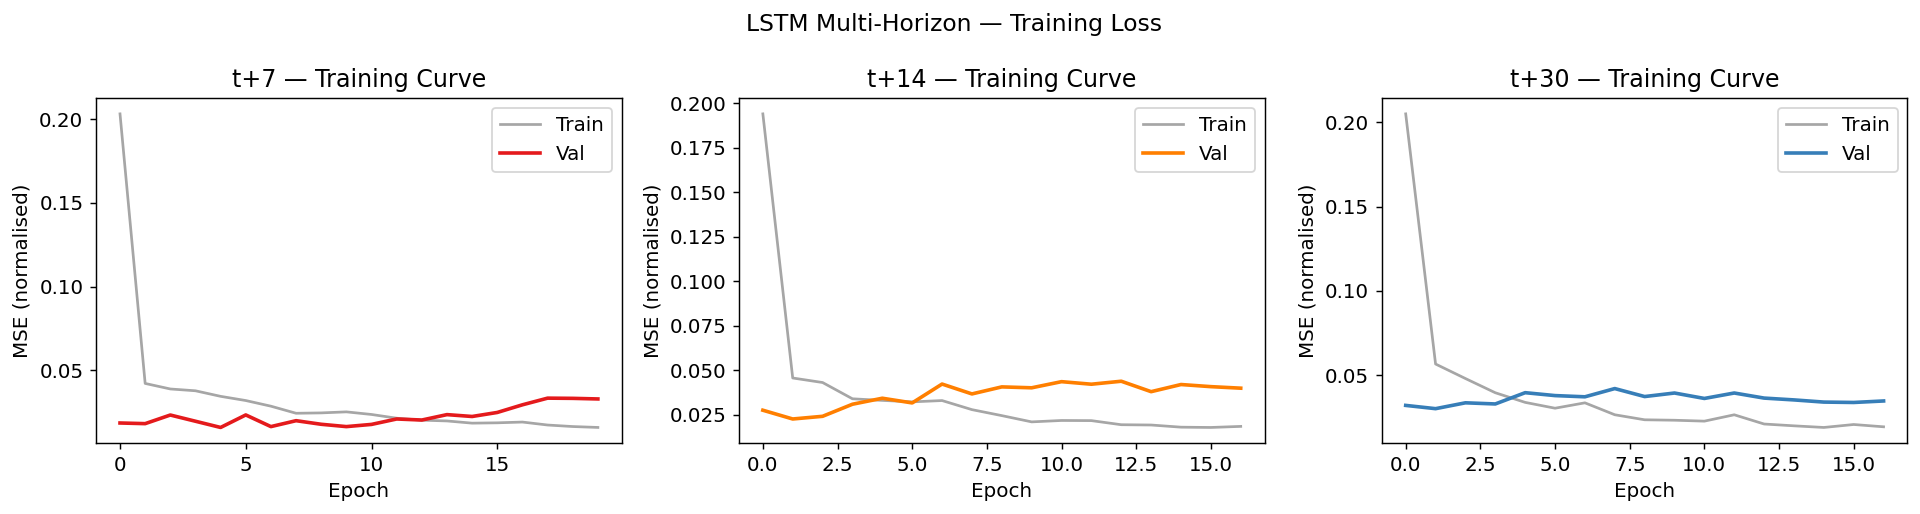

In [5]:
fig, axes = plt.subplots(1, len(all_history), figsize=(5*len(all_history), 4))
if len(all_history) == 1: axes = [axes]
for ax, (h, hist) in zip(axes, all_history.items()):
    ax.plot(hist['train'], label='Train', color='gray', alpha=0.7)
    ax.plot(hist['val'],   label='Val',   color=COLORS[h], linewidth=2)
    ax.set_title(f't+{h} — Training Curve')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE (normalised)')
    ax.legend()
plt.suptitle('LSTM Multi-Horizon — Training Loss', fontsize=13)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'lstm_multihorizon_curves.png', dpi=150)
plt.show()

## 5. Prediction Overlay (Test Set)

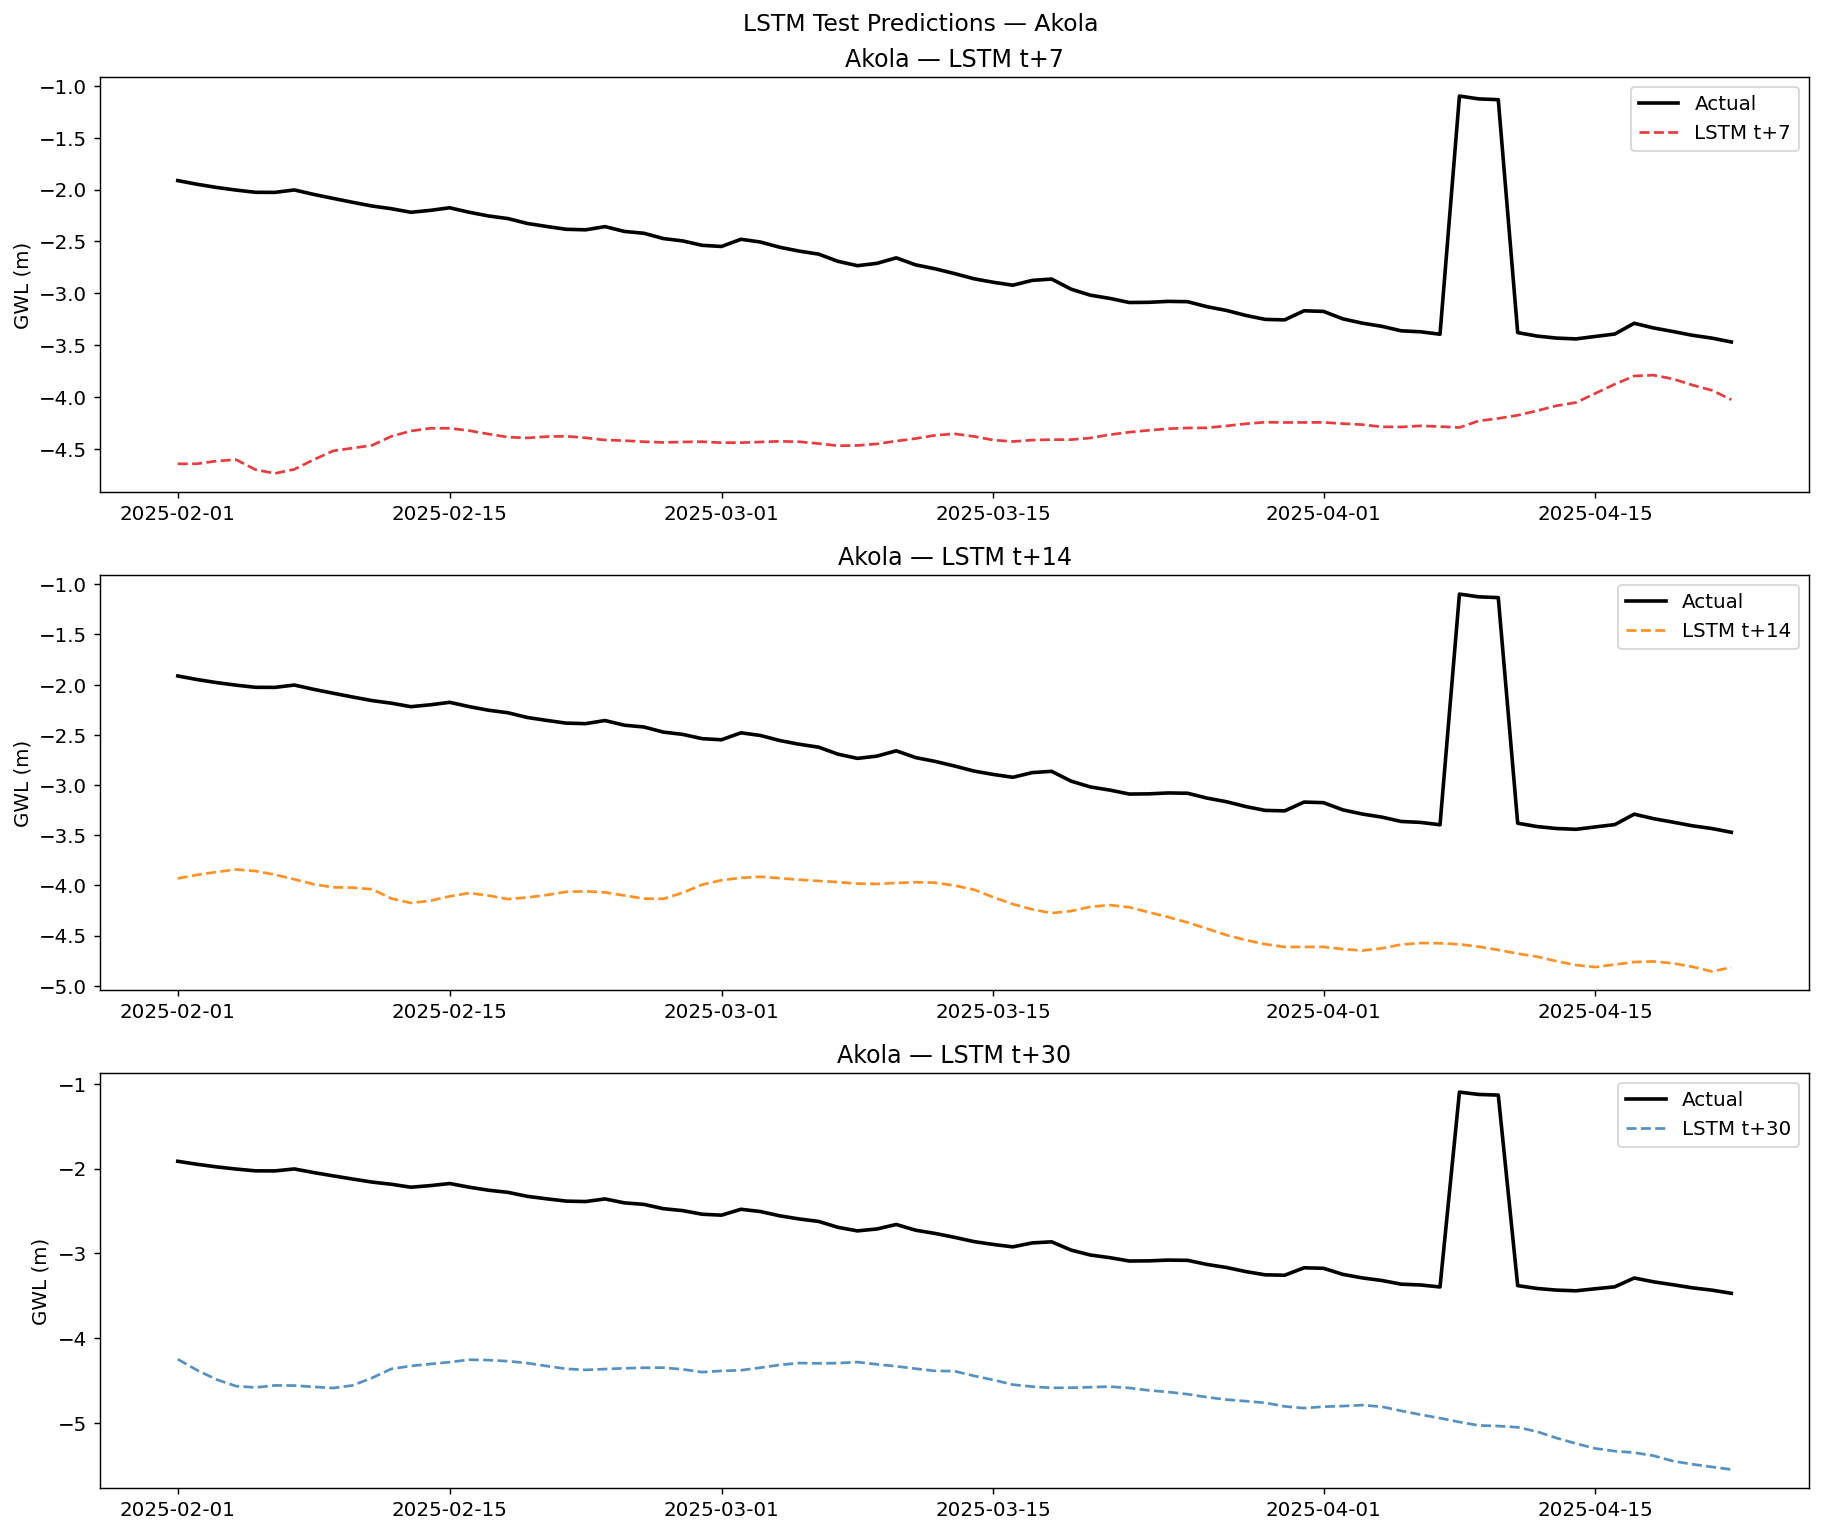

Overlay plot saved for: Akola


In [6]:
# Load all saved predictions and overlay all 3 horizons for the busiest district
pred_frames = {}
for h in HORIZONS:
    p = OUT_DIR / f'lstm_multihorizon_t{h}.csv'
    if p.exists():
        pred_frames[h] = pd.read_csv(p, parse_dates=['date'])

if pred_frames:
    test_frames = {h: df[df['split']=='test'] for h, df in pred_frames.items()}
    if all('district' in v.columns for v in test_frames.values()):
        # Find district with most test points
        plot_dist = test_frames[7].groupby('district').size().idxmax()

        fig, axes = plt.subplots(len(pred_frames), 1,
                                  figsize=(14, 4*len(pred_frames)), sharex=False)
        if len(pred_frames) == 1: axes = [axes]

        for ax, (h, tf) in zip(axes, test_frames.items()):
            sub = tf[tf['district'] == plot_dist].sort_values('date')
            ax.plot(sub['date'], sub['gwl_actual'], label='Actual',
                    color='black', linewidth=2)
            ax.plot(sub['date'], sub['gwl_pred'], label=f'LSTM t+{h}',
                    color=COLORS[h], linewidth=1.5, linestyle='--', alpha=0.85)
            ax.set_title(f'{plot_dist} — LSTM t+{h}')
            ax.set_ylabel('GWL (m)')
            ax.legend()

        plt.suptitle(f'LSTM Test Predictions — {plot_dist}', fontsize=13)
        plt.tight_layout()
        plt.savefig(PLOT_DIR / 'lstm_multihorizon_overlay.png', dpi=150)
        plt.show()
        print(f'Overlay plot saved for: {plot_dist}')

## 6. Summary Table

In [7]:
summary_df = pd.DataFrame(all_summary)
summary_df.to_csv(OUT_DIR / 'lstm_multihorizon_summary.csv', index=False)

print('=== LSTM Multi-Horizon Final Summary ===')
display(
    summary_df.style
    .background_gradient(subset=['Test RMSE','Test MAE'], cmap='YlOrRd')
    .format({'Val RMSE':'{:.4f}','Val MAE':'{:.4f}',
             'Test RMSE':'{:.4f}','Test MAE':'{:.4f}'})
)

=== LSTM Multi-Horizon Final Summary ===


,Horizon,Val RMSE,Val MAE,Test RMSE,Test MAE
0,t+7,2.0140,1.1803,3.2685,1.6505
1,t+14,2.4009,1.4785,4.1763,1.9935
2,t+30,2.7647,1.6390,3.5448,1.8007
